# **Parte 3.2: Clasificación**

7. Clasificación:
    - Escoge una variable objetivo categórica relevante.
    - Codifica adecuadamente las variables predictoras.
    - Divide el dataset en 70% entrenamiento y 30% prueba.
    - Ajusta los siguientes modelos:
        - Árbol de decisión
        - Regresión multinomial
        - CHAID
    - Evalúa con:
        - Matriz de confusión
        - Precisión y recall
        - Curva ROC y AUC
        - Importancia de variables
    - **Compara el desempeño de todos los modelos.**

### **0: Dependencias**

In [1]:
import os
import warnings
from collections import defaultdict

import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    ConfusionMatrixDisplay, classification_report, confusion_matrix,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_curve, roc_auc_score
)

warnings.filterwarnings("ignore", category=UserWarning)   # CHAID avisa de paquetes opcionales para graficar
from CHAID import Tree                                     # pip install CHAID

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

# Carpeta donde se guardan las figuras (se reutilizan en el reporte en PDF)
FIG_DIR = "/home/yagoh/Escritorio/Personal/dev/Educacion/Diplomado-Tecnicas-Estadisticas-y-Mineria-de-Datos/Unidad_3/Tarea/Documentos/Practica_3_2/figures/"
os.makedirs(FIG_DIR, exist_ok=True)


### **1. Variable objetivo**

##### 1.1: Carga del dataset limpio

In [2]:
# Usamos el dataset que resultó de la Práctica Integradora (ya sin duplicados y con NAs/outliers tratados)
path = "/home/yagoh/Escritorio/Personal/dev/Educacion/Diplomado-Tecnicas-Estadisticas-y-Mineria-de-Datos/Unidad_3/Data/Practicas/Netflix_clean.csv"
df = pd.read_csv(path)

print(f"El dataset tiene {df.shape[0]:,} observaciones y {df.shape[1]} variables.")
df.head(1)

El dataset tiene 15,330 observaciones y 31 variables.


,Title,Genre,Tags,Languages,Series or Movie,Hidden Gem Score,Country Availability,Runtime,Director,Writer,...,Netflix Link,IMDb Link,Summary,IMDb Votes,Image,Poster,TMDb Trailer,Trailer Site,IMDb Votes_log,Boxoffice_log
0,Lets Fight Ghost,"Crime, Drama, Fantasy, Horror, Romance","Comedy Programmes,Romantic TV Comedies,Horror ...","Swedish, Spanish",Series,4.3,Thailand,< 30 minutes,Tomas Alfredson,John Ajvide Lindqvist,...,https://www.netflix.com/watch/81415947,https://www.imdb.com/title/tt1139797,A med student with a supernatural gift tries t...,205926.0,https://occ-0-4708-64.1.nflxso.net/dnm/api/v6/...,https://m.media-amazon.com/images/M/MV5BOWM4NT...,NaN,NaN,12.235277,14.567901


##### 1.2: Escoge una variable objetivo categórica relevante

Se usa **`IMDb Score`** convertida en tres clases de calidad: **Baja**, **Media** y **Alta**, cortando en los terciles de la calificación.

Cortes (terciles de IMDb Score): Baja <= 6.3 < Media <= 6.9 < Alta
            Títulos  Proporción
IMDb Score                     
Baja           5473       0.357
Media          4902       0.320
Alta           4955       0.323


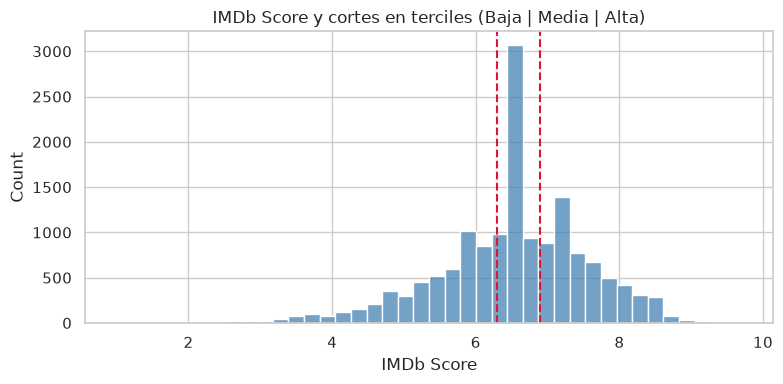

In [3]:
cortes = df["IMDb Score"].quantile([1/3, 2/3]).values
NOMBRES = ["Baja", "Media", "Alta"]                   # 0, 1, 2 (orden ascendente de calificación)
y = pd.cut(df["IMDb Score"], [-np.inf, cortes[0], cortes[1], np.inf], labels=[0, 1, 2]).astype(int)

print(f"Cortes (terciles de IMDb Score): Baja <= {cortes[0]:.1f} < Media <= {cortes[1]:.1f} < Alta")
conteo = y.map(dict(enumerate(NOMBRES))).value_counts().reindex(NOMBRES)
print(pd.DataFrame({"Títulos": conteo, "Proporción": (conteo / conteo.sum()).round(3)}))

plt.figure(figsize=(8, 4))
sns.histplot(df["IMDb Score"], bins=40, color="steelblue")
for c in cortes:
    plt.axvline(c, color="crimson", ls="--")
plt.title("IMDb Score y cortes en terciles (Baja | Media | Alta)")
plt.tight_layout()
plt.savefig(FIG_DIR + "p32_1_objetivo.png", dpi=150)
plt.show()

- Los cortes quedan en 6.3 y 6.9: Baja ≤ 6.3 < Media ≤ 6.9 < Alta.
- Las clases son 35.7% Baja, 32.0% Media y 32.3% Alta (15,330 títulos). Un modelo que siempre dijera "Baja" acertaría 35.7%; ese es el piso para comparar el *accuracy*.

##### 1.3: ¿Hay alguna variable que "delate" el objetivo? (fuga de información)

Se revisan `Hidden Gem Score` y las calificaciones de otras fuentes (`Rotten Tomatoes Score`, `Metacritic Score`).

In [4]:
# 1) Correlación de Spearman con IMDb Score y proporción de NAs de las calificaciones de otras fuentes
cand = ["Hidden Gem Score", "IMDb Votes_log", "Rotten Tomatoes Score", "Metacritic Score"]
pd.DataFrame({
    "Spearman con IMDb Score": [df[c].corr(df["IMDb Score"], method="spearman") for c in cand],
    "% NAs": [df[c].isna().mean() * 100 for c in cand],
}, index=cand).round(3)

,Spearman con IMDb Score,% NAs
Hidden Gem Score,0.170,0.000
IMDb Votes_log,0.164,0.000
Rotten Tomatoes Score,0.732,58.982
Metacritic Score,0.720,72.237


In [5]:
# 2) ¿Qué tanto se puede predecir la clase con cada variable sola o combinada? (árbol sencillo, AUC en prueba)
Xa, Xb, ya, yb = train_test_split(df[["Hidden Gem Score", "IMDb Votes_log"]], y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
filas = []
for cols in (["IMDb Votes_log"], ["Hidden Gem Score"], ["Hidden Gem Score", "IMDb Votes_log"]):
    arbol = DecisionTreeClassifier(max_depth=6, min_samples_leaf=30, random_state=RANDOM_STATE).fit(Xa[cols], ya)
    filas.append({"Variables": " + ".join(cols), "Accuracy": accuracy_score(yb, arbol.predict(Xb[cols])),
                  "AUC (OvR)": roc_auc_score(yb, arbol.predict_proba(Xb[cols]), multi_class="ovr")})
pd.DataFrame(filas).round(3)

,Variables,Accuracy,AUC (OvR)
0,IMDb Votes_log,0.515,0.684
1,Hidden Gem Score,0.703,0.848
2,Hidden Gem Score + IMDb Votes_log,0.792,0.926


- `Hidden Gem Score` casi no correlaciona con el objetivo (Spearman 0.17), pero junto con los votos predice muy bien la clase: con un árbol sencillo el AUC pasa de 0.68 (solo votos) y 0.85 (solo el índice) a 0.93 (las dos). Se deja fuera de las predictoras y se retoma en 7.6.
- `Rotten Tomatoes Score` y `Metacritic Score` sí correlacionan fuerte (0.73 y 0.72), pero les falta el 59.0% y el 72.2% de los datos. Se descartan igual que en la 3.1.
- `IMDb Votes_log` se queda: correlaciona poco (0.16) y no es una calificación.

### **2. Codificación de las variables predictoras**

In [6]:
X = pd.DataFrame(index=df.index)

# --- Numéricas (ya limpias desde la Práctica Integradora) ---
X["IMDb Votes (log)"] = df["IMDb Votes_log"]                       # versión logarítmica por la asimetría

# --- Numéricas derivadas de fechas y texto ---
X["Año en Netflix"] = pd.to_datetime(df["Netflix Release Date"], errors="coerce").dt.year
anio_estreno = pd.to_datetime(df["Release Date"], errors="coerce").dt.year
X["Año de estreno"] = anio_estreno.fillna(anio_estreno.median())  # 14% sin fecha: se imputa con la mediana
X["N° géneros"] = df["Genre"].fillna("").apply(lambda s: len([g for g in s.split(", ") if g]))
X["N° idiomas"] = df["Languages"].fillna("").apply(lambda s: len([i for i in s.split(", ") if i]))

# --- Ordinal: duración (con un solo NA, que se manda a la categoría más frecuente) ---
orden_runtime = {"< 30 minutes": 0, "30-60 mins": 1, "1-2 hour": 2, "> 2 hrs": 3}
X["Duración (ordinal)"] = df["Runtime"].fillna("1-2 hour").map(orden_runtime)

# --- Binarias ---
X["Es serie"] = (df["Series or Movie"] == "Series").astype(int)
X["Idioma: English"] = df["Languages"].fillna("").str.contains("English").astype(int)

# --- Multi-hot: top 12 géneros (un título puede tener varios) ---
top_generos = df["Genre"].dropna().str.split(", ").explode().value_counts().head(12).index
lista_generos = df["Genre"].fillna("").str.split(", ")
for g in top_generos:
    X[f"Género: {g}"] = lista_generos.apply(lambda lst: int(g in lst))

# --- One-hot: clasificación por edad (los NaN se vuelven una categoría propia) ---
view_rating = df["View Rating"].fillna("Desconocido")
for r in view_rating.value_counts().index:
    X[f"Rating: {r}"] = (view_rating == r).astype(int)

print(f"Matriz de predictoras: {X.shape[0]:,} filas x {X.shape[1]} columnas")
print(f"NAs restantes en X: {X.isna().sum().sum()}")

Matriz de predictoras: 15,330 filas x 49 columnas
NAs restantes en X: 0


In [7]:
# Resumen de cómo se codificó cada grupo de variables
n_num = 5
pd.DataFrame({
    "Grupo": ["Numéricas (+ derivadas)", "Ordinal", "Binarias", "Multi-hot (Genre)", "One-hot (View Rating)"],
    "Variables": [n_num, 1, 2, len(top_generos), view_rating.nunique()],
    "Codificación": ["Tal cual (+ estandarización en la regresión)", "< 30 min = 0 ... > 2 hrs = 3",
                     "Es serie / contiene 'English'", "Una columna 0/1 por género frecuente",
                     "Una columna 0/1 por categoría (NaN = Desconocido)"],
})

,Grupo,Variables,Codificación
0,Numéricas (+ derivadas),5,Tal cual (+ estandarización en la regresión)
1,Ordinal,1,< 30 min = 0 ... > 2 hrs = 3
2,Binarias,2,Es serie / contiene 'English'
3,Multi-hot (Genre),12,Una columna 0/1 por género frecuente
4,One-hot (View Rating),29,Una columna 0/1 por categoría (NaN = Desconocido)


- Quedan 49 predictoras sin NAs: 5 numéricas, 1 ordinal (duración), 2 binarias, 12 géneros y 29 categorías de `View Rating`.
- Se dejan fuera los identificadores y textos (`Title`, enlaces, `Summary`, imágenes...) y las variables con más de 50% de NAs (`Boxoffice`, `Metacritic Score`, `Rotten Tomatoes Score`, `Awards *`, `Production House`).

##### 2.1: Codificación para CHAID

CHAID solo trabaja con variables categóricas, así que las numéricas se pasan a quintiles (ordinales) y el resto se deja como texto. Son las mismas variables de los otros dos modelos.

In [8]:
def quintiles(serie, k=5):
    return pd.qcut(serie, k, labels=False, duplicates="drop")

XC = pd.DataFrame(index=df.index)
XC["Votos IMDb"] = quintiles(X["IMDb Votes (log)"])
XC["Año Netflix"] = quintiles(X["Año en Netflix"].rank(method="first"))
XC["Año estreno"] = quintiles(X["Año de estreno"].rank(method="first"))
XC["N géneros"] = X["N° géneros"].clip(upper=4)                      # 4 = "4 o más"
XC["N idiomas"] = X["N° idiomas"].clip(upper=3)                      # 3 = "3 o más"
XC["Duración"] = df["Runtime"].fillna("1-2 hour")
XC["Tipo"] = df["Series or Movie"]
XC["Inglés"] = np.where(X["Idioma: English"] == 1, "Sí", "No")
for g in top_generos:
    XC[f"Género {g}"] = np.where(X[f"Género: {g}"] == 1, "Sí", "No")
XC["Clasificación edad"] = view_rating

ORDINALES = ["Votos IMDb", "Año Netflix", "Año estreno", "N géneros", "N idiomas"]

# Rangos de cada quintil, para poder interpretar el árbol
rangos = {"Votos IMDb": X["IMDb Votes (log)"], "Año Netflix": X["Año en Netflix"], "Año estreno": X["Año de estreno"]}
leyenda = {}
for nombre, serie in rangos.items():
    leyenda[nombre] = serie.groupby(XC[nombre]).agg(["min", "max"])
    print(f"{nombre}: " + " | ".join(f"{int(k)} = [{r['min']:.1f}, {r['max']:.1f}]" for k, r in leyenda[nombre].iterrows()))
print(f"\nVotos IMDb en votos reales: " + " | ".join(
    f"{int(k)} = [{np.expm1(r['min']):,.0f}, {np.expm1(r['max']):,.0f}]" for k, r in leyenda["Votos IMDb"].iterrows()))
print(f"\nPredictoras para CHAID: {XC.shape[1]} (todas categóricas)")

Votos IMDb: 0 = [1.8, 5.9] | 1 = [5.9, 7.5] | 2 = [7.5, 9.3] | 3 = [9.3, 10.7] | 4 = [10.7, 14.7]
Año Netflix: 0 = [2015.0, 2015.0] | 1 = [2015.0, 2017.0] | 2 = [2017.0, 2019.0] | 3 = [2019.0, 2020.0] | 4 = [2020.0, 2021.0]
Año estreno: 0 = [1910.0, 2008.0] | 1 = [2008.0, 2015.0] | 2 = [2015.0, 2016.0] | 3 = [2016.0, 2018.0] | 4 = [2018.0, 2022.0]

Votos IMDb en votos reales: 0 = [5, 350] | 1 = [351, 1,811] | 2 = [1,812, 11,477] | 3 = [11,489, 42,728] | 4 = [42,757, 2,354,197]

Predictoras para CHAID: 21 (todas categóricas)


### **3. División en entrenamiento (70%) y prueba (30%)**

In [9]:
# Estratificamos por la clase de calidad para conservar la proporción en ambos conjuntos; mismos índices para X y XC
idx_train, idx_test = train_test_split(X.index, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
X_train, X_test, y_train, y_test = X.loc[idx_train], X.loc[idx_test], y.loc[idx_train], y.loc[idx_test]
XC_train, XC_test = XC.loc[idx_train], XC.loc[idx_test]

print(f"Entrenamiento: {len(idx_train):,} filas ({len(idx_train) / len(X):.0%})")
print(f"Prueba:        {len(idx_test):,} filas ({len(idx_test) / len(X):.0%})")
print(pd.DataFrame({"Total": y.value_counts(normalize=True), "Train": y_train.value_counts(normalize=True),
                    "Test": y_test.value_counts(normalize=True)}).rename(index=dict(enumerate(NOMBRES))).sort_index().round(3))

Entrenamiento: 10,731 filas (70%)
Prueba:        4,599 filas (30%)
            Total  Train   Test
IMDb Score                     
Alta        0.323  0.323  0.323
Baja        0.357  0.357  0.357
Media       0.320  0.320  0.320


Solo la regresión multinomial se estandariza. Va dentro de un `Pipeline`, así que la media y la desviación se calculan con entrenamiento.

In [10]:
resultados = {}      # métricas globales por modelo
auc_clase = {}       # AUC uno-contra-resto por clase y modelo
curvas_roc = {}      # {modelo: {clase: (fpr, tpr, auc)}}
importancias = {}    # importancia por permutación por modelo
predicciones = {}    # predicciones sobre prueba
probas = {}          # probabilidades sobre prueba (n x 3)
modelos = {}         # modelos ajustados
colores = {"Árbol de decisión": "seagreen", "Regresión multinomial": "steelblue", "CHAID": "darkorange"}

def graficar_matriz(nombre, archivo):
    y_pred = predicciones[nombre]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=NOMBRES, cmap="Blues", ax=axes[0], colorbar=False)
    axes[0].set_title("Conteos")
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=NOMBRES, normalize="true", values_format=".1%",
                                            cmap="Blues", ax=axes[1], colorbar=False)
    axes[1].set_title("Normalizada por fila (recall por clase)")
    for ax in axes:
        ax.grid(False)
        ax.set_xlabel("Clase predicha"); ax.set_ylabel("Clase real")
    plt.suptitle(f"Matriz de confusión: {nombre}", y=1.02)
    plt.tight_layout()
    plt.savefig(FIG_DIR + archivo, dpi=150, bbox_inches="tight")
    plt.show()
    cm = confusion_matrix(y_test, y_pred, normalize="true")
    print(f"Errores graves (Baja predicha como Alta o Alta como Baja): {(cm[0, 2] * (y_test == 0).sum() + cm[2, 0] * (y_test == 2).sum()) / len(y_test):.1%} de los títulos de prueba")
    print(f"Media confundida con una clase extrema: {cm[1, [0, 2]].sum():.1%} de los títulos Media")

def calcular_metricas(nombre):
    y_pred = predicciones[nombre]
    resultados[nombre] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro"),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro"),
        "F1 (macro)": f1_score(y_test, y_pred, average="macro"),
        "AUC (macro, OvR)": roc_auc_score(y_test, probas[nombre], multi_class="ovr", average="macro"),
    }
    print(classification_report(y_test, y_pred, target_names=NOMBRES, digits=3))

def graficar_roc(nombre, archivo):
    plt.figure(figsize=(6.5, 5.2))
    for k, c in zip(range(3), ["indianred", "goldenrod", "seagreen"]):
        fpr, tpr, auc = curvas_roc[nombre][k]
        plt.plot(fpr, tpr, color=c, lw=2, label=f"{NOMBRES[k]} vs. resto (AUC = {auc:.3f})")
    plt.plot([0, 1], [0, 1], "k--", lw=1, label="Azar (AUC = 0.5)")
    plt.xlabel("Tasa de falsos positivos (1 - especificidad)")
    plt.ylabel("Tasa de verdaderos positivos (recall)")
    plt.title(f"Curvas ROC uno-contra-resto: {nombre}\nAUC macro = {resultados[nombre]['AUC (macro, OvR)']:.3f}")
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.savefig(FIG_DIR + archivo, dpi=150)
    plt.show()

def graficar_importancia(nombre, archivo, color, top=15):
    imp = importancias[nombre].head(top).iloc[::-1]
    plt.figure(figsize=(8, 6))
    plt.barh(imp.index, imp["media"], xerr=imp["std"], color=color)
    plt.xlabel("Caída del AUC macro al permutar la variable (en prueba)")
    plt.title(f"Importancia de variables por permutación: {nombre}")
    plt.tight_layout()
    plt.savefig(FIG_DIR + archivo, dpi=150)
    plt.show()
    return importancias[nombre].head(8).round(4)

def evaluar(nombre, modelo, X_te, columnas, n_jobs=-1, n_repeats=10):
    """Predicciones, ROC (uno contra resto) e importancia por permutación sobre el conjunto de prueba."""
    modelos[nombre] = modelo
    predicciones[nombre] = modelo.predict(X_te)
    probas[nombre] = modelo.predict_proba(X_te)
    curvas_roc[nombre] = {}
    for k in range(3):
        fpr, tpr, _ = roc_curve((y_test == k).astype(int), probas[nombre][:, k])
        curvas_roc[nombre][k] = (fpr, tpr, roc_auc_score((y_test == k).astype(int), probas[nombre][:, k]))
    perm = permutation_importance(modelo, X_te, y_test, scoring="roc_auc_ovr", n_repeats=n_repeats,
                                  random_state=RANDOM_STATE, n_jobs=n_jobs)
    importancias[nombre] = (pd.DataFrame({"media": perm.importances_mean, "std": perm.importances_std}, index=columnas)
                            .sort_values("media", ascending=False))

### **4. Árbol de decisión**

##### 4.1: Ajuste del modelo

Se buscan `max_depth`, `min_samples_leaf` y `ccp_alpha` con validación cruzada de 5 pliegues sobre entrenamiento, maximizando el AUC macro.

In [11]:
rejilla_arbol = {
    "max_depth": [3, 4, 5, 6, 8, 10, 12, 15],
    "min_samples_leaf": [10, 30, 60],
    "ccp_alpha": [0, 0.0005, 0.001, 0.002],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
busqueda_arbol = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), rejilla_arbol,
                              scoring="roc_auc_ovr", cv=cv, n_jobs=-1)
busqueda_arbol.fit(X_train, y_train)

print("Mejores hiperparámetros:", busqueda_arbol.best_params_)
print(f"AUC macro en validación cruzada: {busqueda_arbol.best_score_:.3f}")
arbol = busqueda_arbol.best_estimator_
evaluar("Árbol de decisión", arbol, X_test, X.columns)
print(f"Profundidad real: {arbol.get_depth()} | hojas: {arbol.get_n_leaves()}")

Mejores hiperparámetros: {'ccp_alpha': 0, 'max_depth': 15, 'min_samples_leaf': 60}
AUC macro en validación cruzada: 0.804


Profundidad real: 15 | hojas: 127


In [12]:
# Resultados de la búsqueda: mejores combinaciones
(pd.DataFrame(busqueda_arbol.cv_results_)[["param_max_depth", "param_min_samples_leaf", "param_ccp_alpha", "mean_test_score", "std_test_score"]]
 .sort_values("mean_test_score", ascending=False).head(8).round(4).reset_index(drop=True))

,param_max_depth,param_min_samples_leaf,param_ccp_alpha,mean_test_score,std_test_score
0,15,60,0.0000,0.8038,0.0061
1,12,60,0.0000,0.8030,0.0065
2,15,10,0.0005,0.8023,0.0086
3,15,30,0.0005,0.8017,0.0086
4,15,60,0.0005,0.8008,0.0092
5,10,60,0.0000,0.8006,0.0075
6,15,30,0.0000,0.8005,0.0072
7,12,30,0.0005,0.8003,0.0092


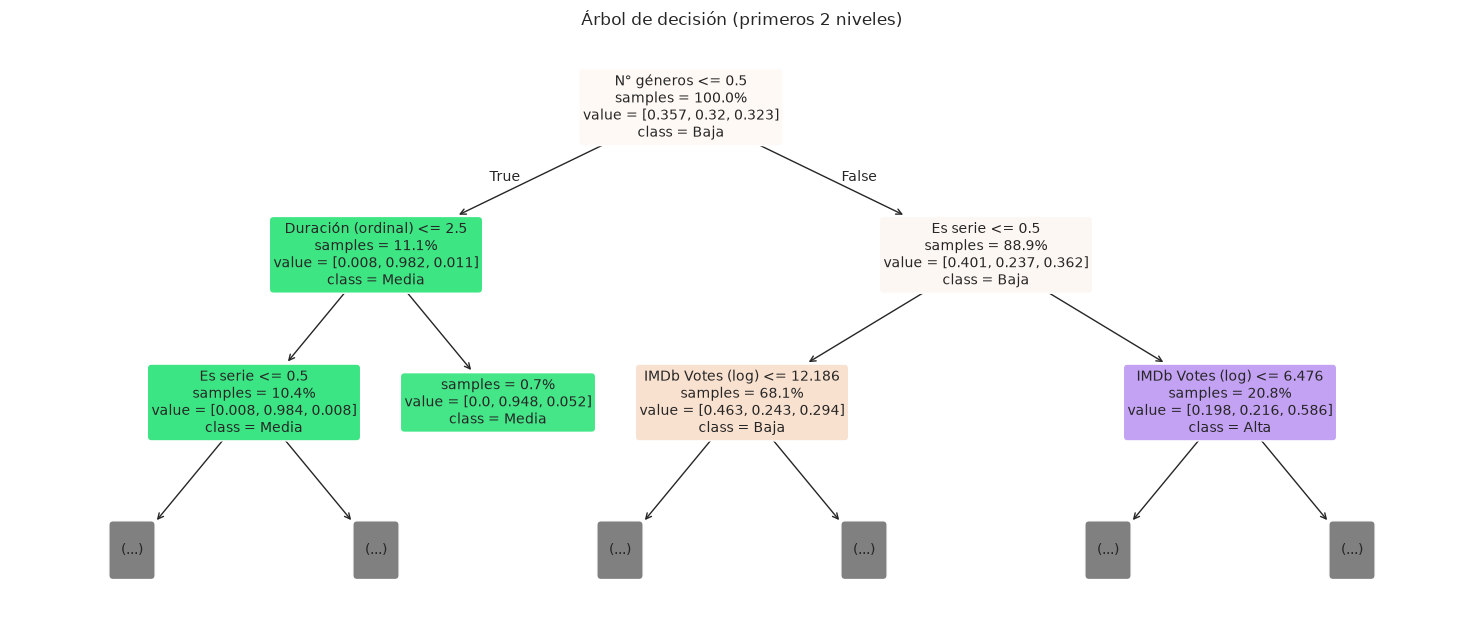

In [13]:
plt.figure(figsize=(15, 6.5))
plot_tree(arbol, max_depth=2, feature_names=X.columns, class_names=NOMBRES, filled=True, rounded=True,
          fontsize=10, proportion=True, impurity=False)
plt.title("Árbol de decisión (primeros 2 niveles)")
plt.tight_layout()
plt.savefig(FIG_DIR + "p32_4_arbol.png", dpi=130)
plt.show()

##### 4.2: Matriz de confusión

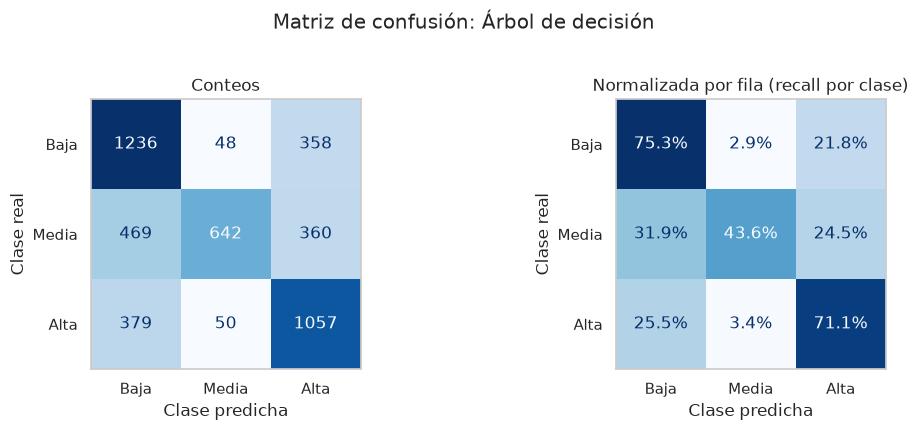

Errores graves (Baja predicha como Alta o Alta como Baja): 16.0% de los títulos de prueba
Media confundida con una clase extrema: 56.4% de los títulos Media


In [14]:
graficar_matriz("Árbol de decisión", "p32_4_arbol_matriz.png")

##### 4.3: Precisión y recall

In [15]:
calcular_metricas("Árbol de decisión")

              precision    recall  f1-score   support

        Baja      0.593     0.753     0.663      1642
       Media      0.868     0.436     0.581      1471
        Alta      0.595     0.711     0.648      1486

    accuracy                          0.638      4599
   macro avg      0.685     0.633     0.631      4599
weighted avg      0.682     0.638     0.632      4599



##### 4.4: Curva ROC y AUC

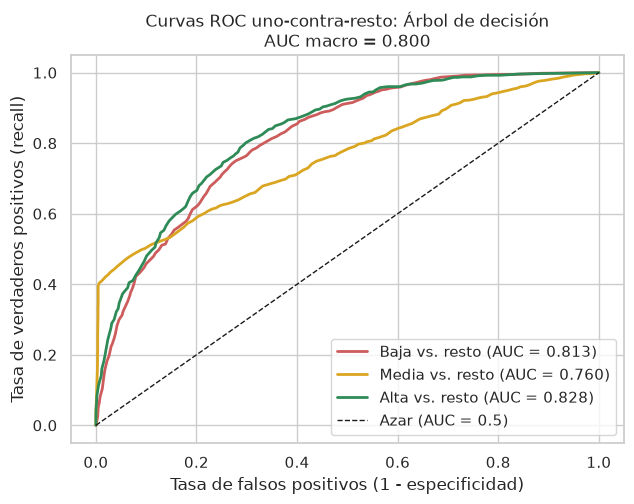

In [16]:
graficar_roc("Árbol de decisión", "p32_4_arbol_roc.png")

##### 4.5: Importancia de variables

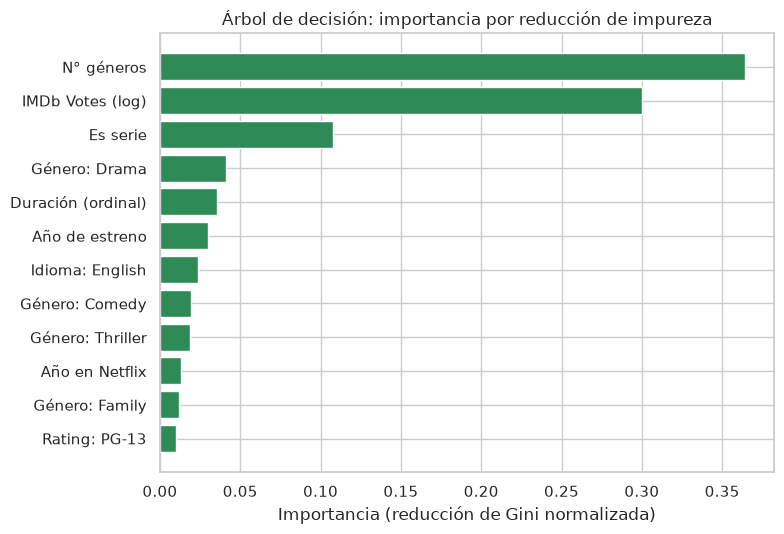

,Importancia Gini
N° géneros,0.364
IMDb Votes (log),0.300
Es serie,0.108
Género: Drama,0.041
Duración (ordinal),0.035
Año de estreno,0.030
Idioma: English,0.024
Género: Comedy,0.019


In [17]:
# Importancia propia del árbol (reducción total de impureza de Gini que aporta cada variable)
imp_gini = pd.Series(arbol.feature_importances_, index=X.columns).sort_values(ascending=False)
top = imp_gini.head(12).iloc[::-1]
plt.figure(figsize=(8, 5.5))
plt.barh(top.index, top.values, color="seagreen")
plt.xlabel("Importancia (reducción de Gini normalizada)")
plt.title("Árbol de decisión: importancia por reducción de impureza")
plt.tight_layout()
plt.savefig(FIG_DIR + "p32_4_arbol_gini.png", dpi=150)
plt.show()
imp_gini.head(8).round(3).to_frame("Importancia Gini")

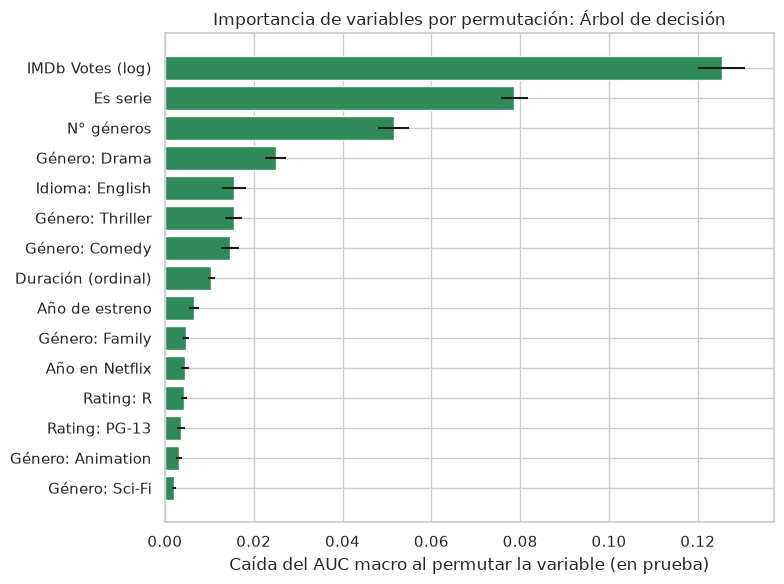

,media,std
IMDb Votes (log),0.1253,0.0053
Es serie,0.0787,0.0029
N° géneros,0.0515,0.0035
Género: Drama,0.0249,0.0023
Idioma: English,0.0156,0.0027
Género: Thriller,0.0155,0.0019
Género: Comedy,0.0147,0.0020
Duración (ordinal),0.0105,0.0008


In [18]:
# Para comparar los tres modelos con el mismo criterio, también la importancia por permutación
graficar_importancia("Árbol de decisión", "p32_4_arbol_permutacion.png", "seagreen")

- **Hiperparámetros:** `max_depth=15`, `min_samples_leaf=60`, `ccp_alpha=0` (AUC macro en validación cruzada 0.804). Queda en el borde de la rejilla, pero las 8 mejores combinaciones difieren en menos de 0.004 de AUC. El árbol final tiene profundidad 15 y 127 hojas.
- **Lectura del árbol:** la raíz separa a los títulos sin géneros (11.1% del entrenamiento), que son 98% Media. Con géneros, divide por `Es serie`: las películas (68.1%) son 46% Baja y las series (20.8%) son 59% Alta. En las películas el siguiente corte son los votos (`IMDb Votes (log)` ≤ 12.19, unos 196,000 votos) y en las series también (≤ 6.48, unos 650 votos).
- **Matriz de confusión:** acierta 63.8% de los 4,599 títulos de prueba (piso de 35.7%). Los errores graves, Baja predicha como Alta o al revés, son 16.0%. A Media la confunde con una clase extrema en 56.4% de los casos.
- **Precisión y recall:** Baja 0.593 / 0.753, Media 0.868 / 0.436, Alta 0.595 / 0.711. Macro: precisión 0.685, recall 0.633, F1 0.631. La precisión de Media es alta porque el árbol manda a Media a los títulos sin géneros, que en entrenamiento son 98% Media (coinciden con las calificaciones imputadas).
- **ROC y AUC:** AUC macro 0.800. Por clase: Alta 0.828, Baja 0.813, Media 0.760.
- **Importancia:** por impureza, `N° géneros` (0.364), `IMDb Votes (log)` (0.300) y `Es serie` (0.108). Por permutación el orden cambia: votos (0.125), serie (0.079) y N° géneros (0.052), seguidas de Drama (0.025).

### **5. Regresión multinomial**

##### 5.1: Ajuste del modelo

`LogisticRegression` con `lbfgs` ajusta directamente el modelo multinomial (softmax). Se busca `C` con la misma validación cruzada.

In [19]:
pipe_mult = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(solver="lbfgs", max_iter=3000)),
])
busqueda_mult = GridSearchCV(pipe_mult, {"clf__C": [0.001, 0.01, 0.1, 1, 10, 100]},
                             scoring="roc_auc_ovr", cv=cv, n_jobs=-1)
busqueda_mult.fit(X_train, y_train)

print("Mejor C:", busqueda_mult.best_params_["clf__C"], f"| AUC macro en validación cruzada: {busqueda_mult.best_score_:.3f}")
mult = busqueda_mult.best_estimator_
evaluar("Regresión multinomial", mult, X_test, X.columns)
# Comprobación: las probabilidades de las tres clases suman 1 (softmax)
print("Suma de probabilidades por fila (min, max):", probas["Regresión multinomial"].sum(axis=1).min().round(6), probas["Regresión multinomial"].sum(axis=1).max().round(6))

Mejor C: 100 | AUC macro en validación cruzada: 0.769


Suma de probabilidades por fila (min, max): 1.0 1.0


##### 5.2: Matriz de confusión

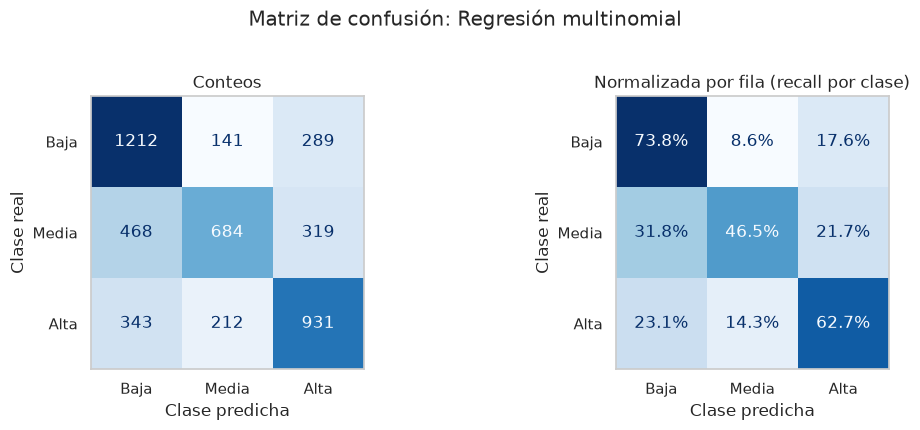

Errores graves (Baja predicha como Alta o Alta como Baja): 13.7% de los títulos de prueba
Media confundida con una clase extrema: 53.5% de los títulos Media


In [20]:
graficar_matriz("Regresión multinomial", "p32_5_mult_matriz.png")

##### 5.3: Precisión y recall

In [21]:
calcular_metricas("Regresión multinomial")

              precision    recall  f1-score   support

        Baja      0.599     0.738     0.661      1642
       Media      0.660     0.465     0.545      1471
        Alta      0.605     0.627     0.616      1486

    accuracy                          0.615      4599
   macro avg      0.621     0.610     0.607      4599
weighted avg      0.620     0.615     0.609      4599



##### 5.4: Curva ROC y AUC

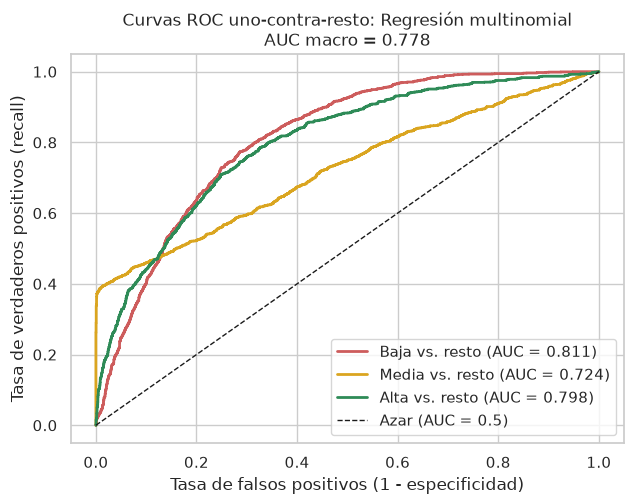

In [22]:
graficar_roc("Regresión multinomial", "p32_5_mult_roc.png")

##### 5.5: Importancia de variables

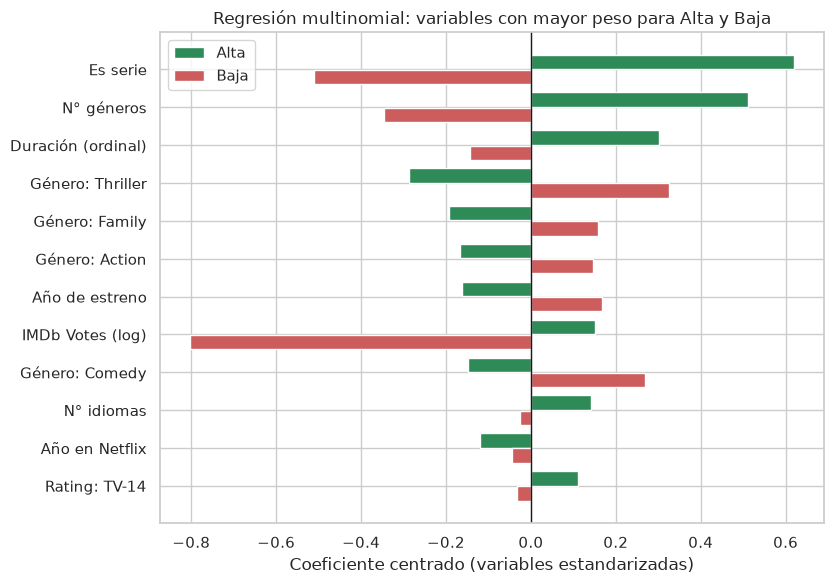

,Baja,Media,Alta
Es serie,-0.512,-0.108,0.619
N° géneros,-0.345,-0.166,0.511
Duración (ordinal),-0.143,-0.160,0.303
Género: Thriller,0.324,-0.037,-0.287
Género: Family,0.159,0.033,-0.192
Género: Action,0.145,0.022,-0.167
Año de estreno,0.167,-0.005,-0.162
IMDb Votes (log),-0.803,0.652,0.151
Género: Comedy,0.269,-0.122,-0.147
N° idiomas,-0.026,-0.115,0.141


In [23]:
# Con variables estandarizadas, cada coeficiente es el cambio en el log-odds de la clase (frente a la clase de referencia)
# por +1 desviación estándar de la variable. Aquí se grafican los de las clases extremas: Alta y Baja.
coefs = pd.DataFrame(mult.named_steps["clf"].coef_.T, index=X.columns, columns=NOMBRES)
# En softmax los coeficientes están definidos salvo una constante: se centra por variable para poder leerlos
coefs_c = coefs.sub(coefs.mean(axis=1), axis=0)
orden = coefs_c["Alta"].abs().sort_values(ascending=False).head(12).index[::-1]

fig, ax = plt.subplots(figsize=(8.5, 6))
y_pos = np.arange(len(orden))
ax.barh(y_pos + 0.2, coefs_c.loc[orden, "Alta"], height=0.38, color="seagreen", label="Alta")
ax.barh(y_pos - 0.2, coefs_c.loc[orden, "Baja"], height=0.38, color="indianred", label="Baja")
ax.set_yticks(y_pos); ax.set_yticklabels(orden)
ax.axvline(0, color="k", lw=1)
ax.set_xlabel("Coeficiente centrado (variables estandarizadas)")
ax.set_title("Regresión multinomial: variables con mayor peso para Alta y Baja")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR + "p32_5_mult_coeficientes.png", dpi=150)
plt.show()
coefs_c.loc[orden[::-1]].round(3)

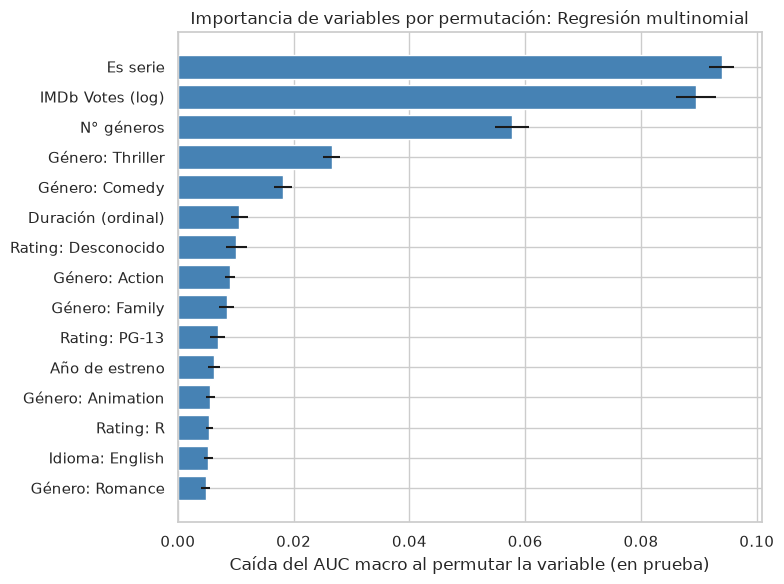

,media,std
Es serie,0.0939,0.0021
IMDb Votes (log),0.0895,0.0034
N° géneros,0.0577,0.0029
Género: Thriller,0.0265,0.0014
Género: Comedy,0.0182,0.0015
Duración (ordinal),0.0106,0.0015
Rating: Desconocido,0.0101,0.0018
Género: Action,0.0090,0.0008


In [24]:
graficar_importancia("Regresión multinomial", "p32_5_mult_permutacion.png", "steelblue")

- **Hiperparámetros:** `C=100`, es decir casi sin regularización (AUC macro en validación cruzada 0.769). Las probabilidades de las tres clases suman 1.
- **Matriz de confusión:** acierta 61.5%. Errores graves de 13.7%, menos que el árbol (16.0%). A Media la manda a una clase extrema en 53.5% de los casos.
- **Precisión y recall:** Baja 0.599 / 0.738, Media 0.660 / 0.465, Alta 0.605 / 0.627. Macro: precisión 0.621, recall 0.610, F1 0.607.
- **ROC y AUC:** AUC macro 0.778 (Baja 0.811, Alta 0.798, Media 0.724).
- **Importancia:** ser serie (+0.62 hacia Alta, -0.51 hacia Baja), tener más géneros (+0.51 / -0.35) y mayor duración (+0.30 / -0.14) empujan hacia Alta; Thriller (+0.32 hacia Baja) y Comedia (+0.27) empujan hacia Baja. Los votos tienen un efecto raro: pocos votos empujan a Baja (-0.80) y votos medios a Media (+0.65), lo que es consistente con que todos los títulos imputados tienen 42,728 votos. Por permutación: serie (0.094), votos (0.090), N° géneros (0.058), Thriller (0.027).

### **6. CHAID**

##### 6.1: Ajuste del modelo

La librería `CHAID` no trae `predict` para datos nuevos, así que se envuelve en una clase compatible con `scikit-learn`. Las probabilidades salen de las proporciones de clase en cada hoja (con suavizado de Laplace). Se busca `max_depth` y `min_child` con la misma validación cruzada.

In [25]:
NOMBRES_CHAID = {0: "Baja", 1: "Media", 2: "Alta"}

class CHAIDClasificador(BaseEstimator, ClassifierMixin):
    """Envoltura de CHAID.Tree con interfaz scikit-learn. Recibe un DataFrame categórico."""

    def __init__(self, ordinales=(), max_depth=3, min_parent=100, min_child=50, alpha_merge=0.05):
        self.ordinales = ordinales
        self.max_depth = max_depth
        self.min_parent = min_parent
        self.min_child = min_child
        self.alpha_merge = alpha_merge

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        d = X.reset_index(drop=True).copy()
        d["__objetivo"] = [NOMBRES_CHAID[k] for k in np.asarray(y)]
        tipos = {c: ("ordinal" if c in self.ordinales else "nominal") for c in X.columns}
        self.arbol_ = Tree.from_pandas_df(d, tipos, "__objetivo", alpha_merge=self.alpha_merge,
                                          max_depth=self.max_depth, min_parent_node_size=self.min_parent,
                                          min_child_node_size=self.min_child)
        self.hijos_ = defaultdict(list)
        for nodo in self.arbol_.tree_store:
            if nodo.parent is not None:
                self.hijos_[nodo.parent].append(nodo)
        self.columnas_ = list(X.columns)
        return self

    def _cuentas(self, nodo):
        c = np.array([nodo.members.get(NOMBRES_CHAID[k], 0) for k in self.classes_], dtype=float)
        return (c + 1) / (c.sum() + len(c))          # suavizado de Laplace

    def _recorre(self, nodo, X, pos, P):
        hijos = self.hijos_.get(nodo.node_id, [])
        if not hijos:
            P[pos] = self._cuentas(nodo)
            return
        col = X[nodo.split.column].to_numpy()[pos]
        resto = np.ones(len(pos), dtype=bool)
        for h in hijos:
            m = np.isin(col, h.choices)
            resto &= ~m
            if m.any():
                self._recorre(h, X, pos[m], P)
        if resto.any():                               # categoría no vista en entrenamiento: se queda en este nodo
            P[pos[resto]] = self._cuentas(nodo)

    def predict_proba(self, X):
        P = np.zeros((len(X), len(self.classes_)))
        self._recorre(self.arbol_.tree_store[0], X, np.arange(len(X)), P)
        return P

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]

    def importancia_chi2(self):
        """Suma del estadístico χ² de los nodos donde se usó cada variable, normalizado."""
        acum = defaultdict(float); usos = defaultdict(int)
        for nodo in self.arbol_.tree_store:
            if self.hijos_.get(nodo.node_id):
                acum[nodo.split.column] += nodo.split.score; usos[nodo.split.column] += 1
        s = pd.DataFrame({"χ² acumulado": pd.Series(acum), "Divisiones": pd.Series(usos)})
        s["Importancia"] = s["χ² acumulado"] / s["χ² acumulado"].sum()
        return s.sort_values("χ² acumulado", ascending=False)

In [26]:
# Búsqueda de profundidad máxima y tamaño mínimo de nodo hijo con validación cruzada (solo sobre entrenamiento).
# alpha_merge = 0.05 es el valor estándar de CHAID: se fusionan categorías con p > 0.05.
busqueda_chaid = GridSearchCV(
    CHAIDClasificador(ordinales=ORDINALES, alpha_merge=0.05),
    {"max_depth": [2, 3, 4, 5, 6, 7], "min_child": [30, 60, 120]},
    scoring="roc_auc_ovr", cv=cv, n_jobs=1)
busqueda_chaid.fit(XC_train, y_train)

print("Mejores hiperparámetros:", busqueda_chaid.best_params_)
print(f"AUC macro en validación cruzada: {busqueda_chaid.best_score_:.3f}")
chaid = busqueda_chaid.best_estimator_
evaluar("CHAID", chaid, XC_test, XC.columns, n_jobs=1, n_repeats=5)
hojas = [n for n in chaid.arbol_.tree_store if not chaid.hijos_.get(n.node_id)]
print(f"Nodos totales: {len(chaid.arbol_.tree_store)} | hojas: {len(hojas)}")

Mejores hiperparámetros: {'max_depth': 7, 'min_child': 30}
AUC macro en validación cruzada: 0.781


Nodos totales: 247 | hojas: 140


In [27]:
(pd.DataFrame(busqueda_chaid.cv_results_)[["param_max_depth", "param_min_child", "mean_test_score", "std_test_score"]]
 .sort_values("mean_test_score", ascending=False).head(8).round(4).reset_index(drop=True))

,param_max_depth,param_min_child,mean_test_score,std_test_score
0,7,30,0.7815,0.0124
1,6,30,0.7795,0.0111
2,5,30,0.7769,0.0098
3,7,60,0.7761,0.0110
4,6,60,0.7761,0.0108
5,5,60,0.7741,0.0101
6,6,120,0.7685,0.0146
7,7,120,0.7685,0.0146


In [28]:
def imprimir_chaid(modelo, max_nivel=2):
    """Árbol CHAID en texto hasta cierto nivel: cada línea es un nodo con su n y la distribución de clases."""
    def linea(n):
        m = np.array([n.members.get(NOMBRES_CHAID[k], 0) for k in range(3)], dtype=float)
        return f"n={int(m.sum()):>5,} | Baja {m[0]/m.sum():4.0%} | Media {m[1]/m.sum():4.0%} | Alta {m[2]/m.sum():4.0%}"
    def rec(n, nivel):
        hs = modelo.hijos_.get(n.node_id, [])
        if not hs:
            return
        for h in hs:
            grupo = ", ".join(str(c) for c in h.choices)
            print("    " * nivel + f"{n.split.column} in {{{grupo}}}  ->  {linea(h)}")
            if nivel + 1 < max_nivel:
                rec(h, nivel + 1)
    raiz = modelo.arbol_.tree_store[0]
    print(f"RAÍZ: {linea(raiz)}  |  se divide por: {raiz.split.column} (χ² = {raiz.split.score:.0f}, p = {raiz.split.p:.1e})\n")
    rec(raiz, 0)

imprimir_chaid(chaid, max_nivel=2)
print(f"\n(El árbol completo tiene {len(chaid.arbol_.tree_store)} nodos y {len(hojas)} hojas; aquí se muestran solo los dos primeros niveles.)")

RAÍZ: n=10,731 | Baja  36% | Media  32% | Alta  32%  |  se divide por: N géneros (χ² = 2764, p = 0.0e+00)

N géneros in {0}  ->  n=1,196 | Baja   1% | Media  98% | Alta   1%
    N idiomas in {0}  ->  n=1,149 | Baja   0% | Media  99% | Alta   1%
    N idiomas in {1, 2, 3}  ->  n=   47 | Baja  17% | Media  68% | Alta  15%
N géneros in {1}  ->  n=2,533 | Baja  43% | Media  25% | Alta  32%
    Votos IMDb in {0}  ->  n=  997 | Baja  53% | Media  19% | Alta  28%
    Votos IMDb in {1}  ->  n=  702 | Baja  46% | Media  22% | Alta  32%
    Votos IMDb in {2}  ->  n=  448 | Baja  36% | Media  18% | Alta  46%
    Votos IMDb in {3}  ->  n=  279 | Baja  15% | Media  64% | Alta  21%
    Votos IMDb in {4}  ->  n=  107 | Baja  29% | Media  16% | Alta  55%
N géneros in {2, 3}  ->  n=4,866 | Baja  41% | Media  23% | Alta  36%
    Duración in {1-2 hour}  ->  n=2,954 | Baja  53% | Media  24% | Alta  24%
    Duración in {30-60 mins, > 2 hrs}  ->  n=  846 | Baja  26% | Media  25% | Alta  49%
    Duración in 

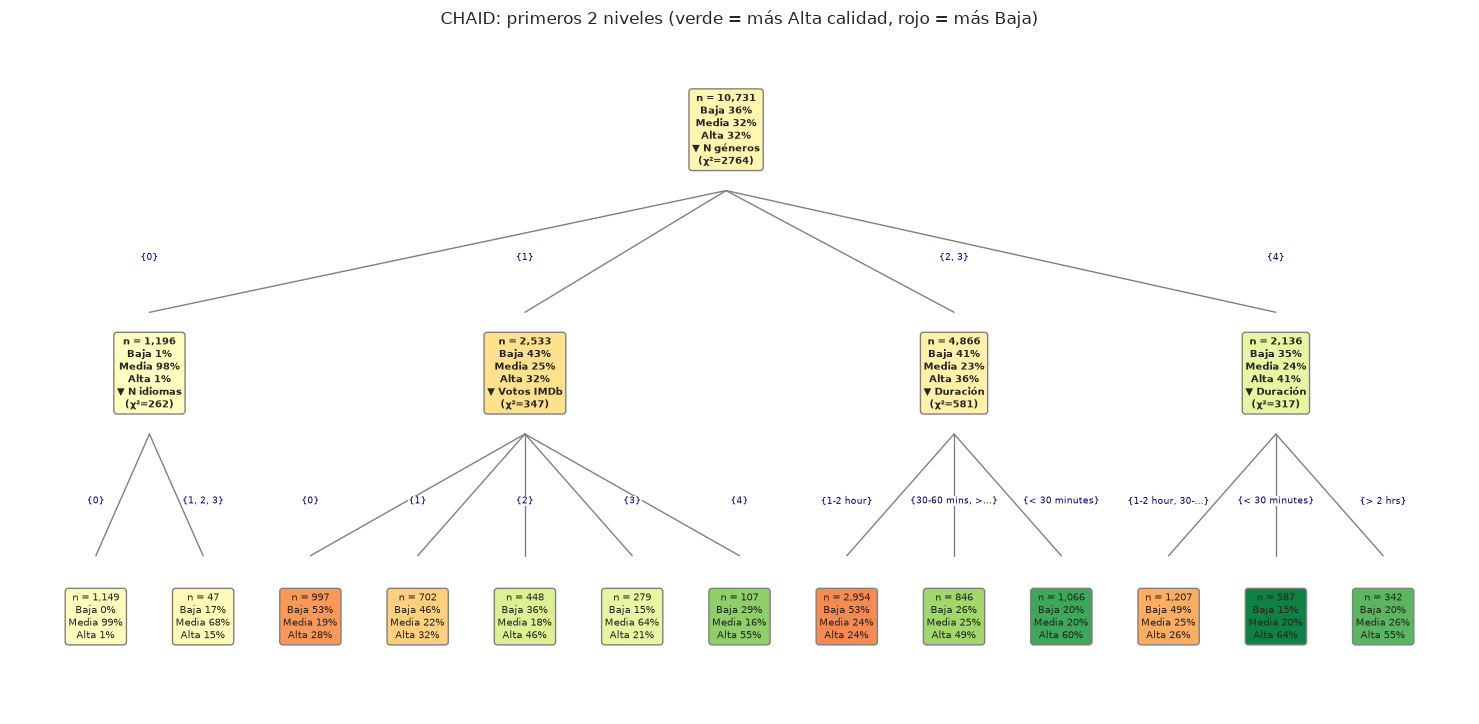

In [29]:
def dibujar_chaid(modelo, profundidad=2, archivo=None):
    """Dibuja los primeros niveles del árbol CHAID: cada caja muestra n, la distribución de clases y la variable que divide."""
    posx, cont = {}, [0]
    def asigna_x(n, nivel=0):
        hs = modelo.hijos_.get(n.node_id, []) if nivel < profundidad else []
        if not hs:
            posx[n.node_id] = float(cont[0]); cont[0] += 1
        else:
            posx[n.node_id] = float(np.mean([asigna_x(h, nivel + 1) for h in hs]))
        return posx[n.node_id]
    raiz = modelo.arbol_.tree_store[0]
    asigna_x(raiz)

    def etiqueta(valores, ancho=15):
        t = "{" + ", ".join(str(v) for v in valores) + "}"
        return t if len(t) <= ancho else t[:ancho - 1] + "…}"

    fig, ax = plt.subplots(figsize=(max(13, cont[0] * 1.15), 7.4))
    def recorre(n, nivel=0, etiq=None):
        m = np.array([n.members.get(NOMBRES_CHAID[k], 0) for k in range(3)], dtype=float)
        p = m / m.sum()
        hs = modelo.hijos_.get(n.node_id, []) if nivel < profundidad else []
        x, yy = posx[n.node_id], -2.0 * nivel
        txt = f"n = {int(m.sum()):,}\nBaja {p[0]:.0%}\nMedia {p[1]:.0%}\nAlta {p[2]:.0%}"
        if hs:
            txt += f"\n▼ {n.split.column}\n(χ²={n.split.score:.0f})"
        ax.text(x, yy, txt, ha="center", va="center", fontsize=7.5, fontweight="bold" if hs else "normal",
                bbox=dict(boxstyle="round", fc=plt.cm.RdYlGn(0.5 + (p[2] - p[0]) * 0.9), ec="gray"), zorder=3)
        for h in hs:
            xh, yh = posx[h.node_id], -2.0 * (nivel + 1)
            ax.plot([x, xh], [yy - 0.5, yh + 0.5], color="gray", lw=1, zorder=1)
            ax.text(xh, yh + 0.95, etiqueta(h.choices), ha="center", va="center", fontsize=6.5, color="navy",
                    bbox=dict(fc="white", ec="none", pad=0.4), zorder=2)
            recorre(h, nivel + 1)
    recorre(raiz)
    ax.set_ylim(-2.0 * profundidad - 0.8, 0.8); ax.set_xlim(-0.8, cont[0] - 0.2); ax.axis("off")
    ax.set_title(f"CHAID: primeros {profundidad} niveles (verde = más Alta calidad, rojo = más Baja)")
    plt.tight_layout()
    if archivo: plt.savefig(FIG_DIR + archivo, dpi=140)
    plt.show()

dibujar_chaid(chaid, profundidad=2, archivo="p32_6_chaid_arbol.png")

##### 6.2: Matriz de confusión

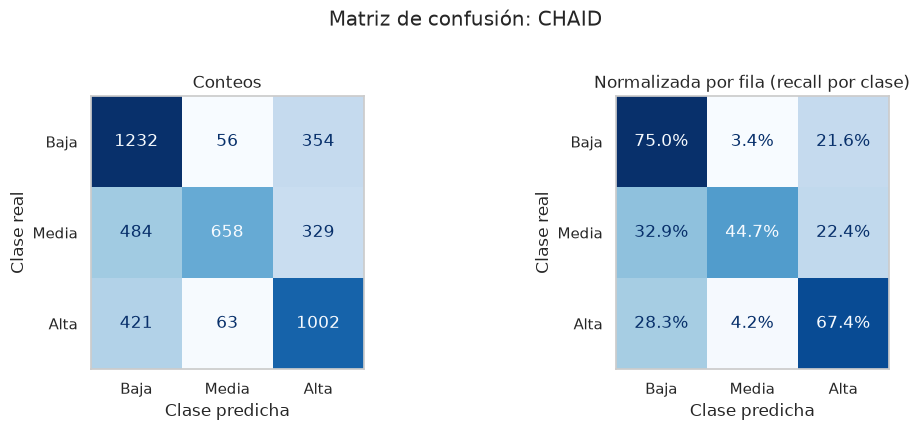

Errores graves (Baja predicha como Alta o Alta como Baja): 16.9% de los títulos de prueba
Media confundida con una clase extrema: 55.3% de los títulos Media


In [30]:
graficar_matriz("CHAID", "p32_6_chaid_matriz.png")

##### 6.3: Precisión y recall

In [31]:
calcular_metricas("CHAID")

              precision    recall  f1-score   support

        Baja      0.577     0.750     0.652      1642
       Media      0.847     0.447     0.585      1471
        Alta      0.595     0.674     0.632      1486

    accuracy                          0.629      4599
   macro avg      0.673     0.624     0.623      4599
weighted avg      0.669     0.629     0.624      4599



##### 6.4: Curva ROC y AUC

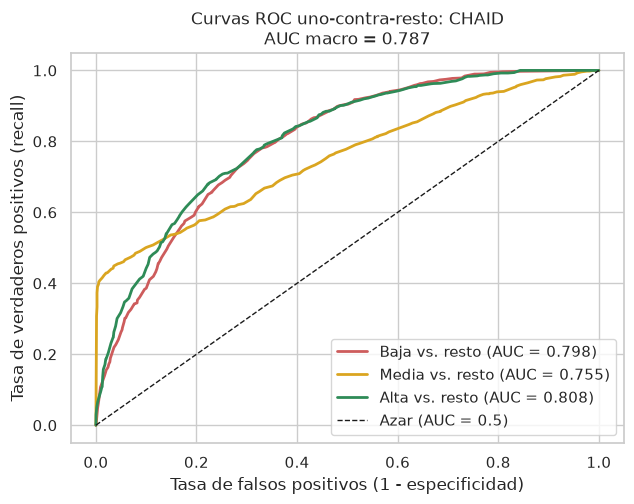

In [32]:
graficar_roc("CHAID", "p32_6_chaid_roc.png")

##### 6.5: Importancia de variables

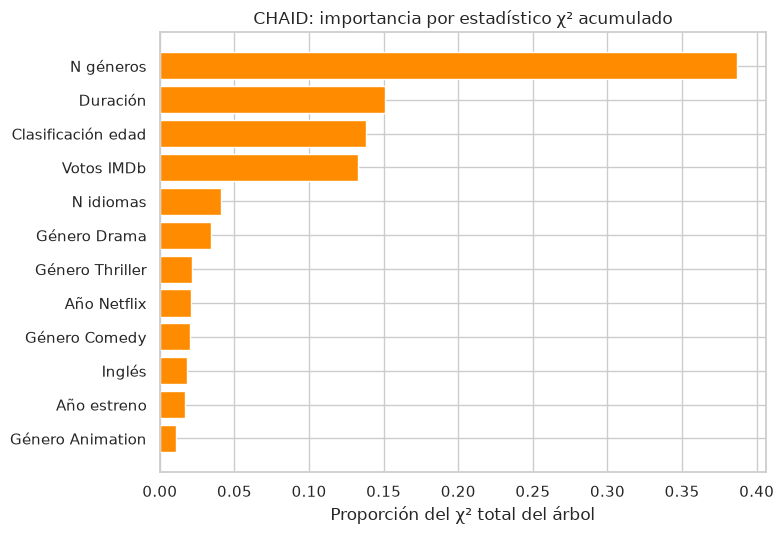

,χ² acumulado,Divisiones,Importancia
N géneros,2789.291,3,0.387
Duración,1086.097,7,0.151
Clasificación edad,997.237,23,0.138
Votos IMDb,955.232,10,0.132
N idiomas,297.283,4,0.041
Género Drama,247.929,9,0.034
Género Thriller,152.945,7,0.021
Año Netflix,151.521,11,0.021


In [33]:
# Importancia propia de CHAID: suma del estadístico χ² de las divisiones donde participa cada variable
imp_chi = chaid.importancia_chi2()
top = imp_chi.head(12).iloc[::-1]
plt.figure(figsize=(8, 5.5))
plt.barh(top.index, top["Importancia"], color="darkorange")
plt.xlabel("Proporción del χ² total del árbol")
plt.title("CHAID: importancia por estadístico χ² acumulado")
plt.tight_layout()
plt.savefig(FIG_DIR + "p32_6_chaid_chi2.png", dpi=150)
plt.show()
imp_chi.head(8).round(3)

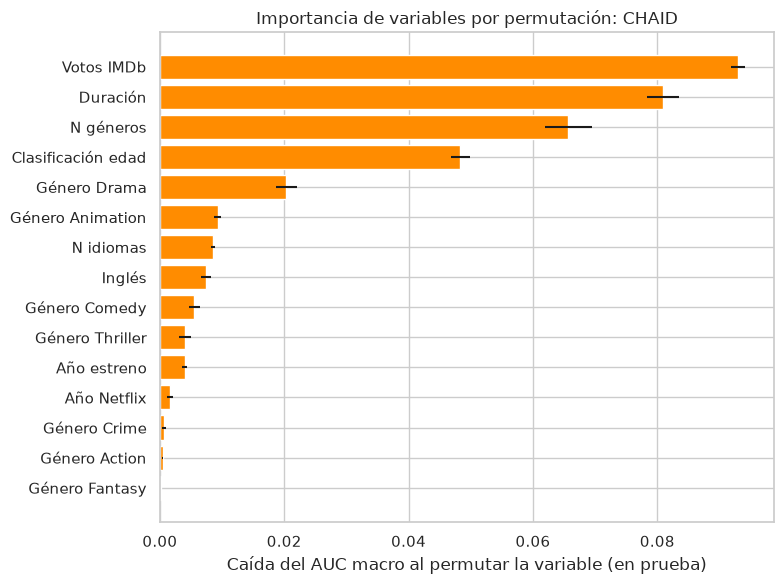

,media,std
Votos IMDb,0.0929,0.0011
Duración,0.0809,0.0026
N géneros,0.0657,0.0038
Clasificación edad,0.0483,0.0015
Género Drama,0.0203,0.0017
Género Animation,0.0093,0.0006
N idiomas,0.0085,0.0003
Inglés,0.0074,0.0008


In [34]:
graficar_importancia("CHAID", "p32_6_chaid_permutacion.png", "darkorange")

In [35]:
# ¿Por qué CHAID usa Duración y no "Es serie"? Mira cuánto se parecen: casi todas las series caen en "< 30 minutes"
pd.crosstab(df["Runtime"].fillna("1-2 hour"), df["Series or Movie"], margins=True)

Series or Movie,Movie,Series,All
Runtime,,,
1-2 hour,9044,1,9045
30-60 mins,333,0,333
< 30 minutes,214,3739,3953
> 2 hrs,1999,0,1999
All,11590,3740,15330


- **Hiperparámetros:** `max_depth=7` y `min_child=30` (AUC macro en validación cruzada 0.781). El árbol tiene 247 nodos y 140 hojas, demasiado grande para leerlo completo; en el notebook se muestran los dos primeros niveles.
- **Lectura del árbol:** la raíz divide por `N géneros` (χ² = 2,764). Los 1,196 títulos sin géneros son 98% Media. Con 2 o 3 géneros, los de menos de 30 minutos son 60% Alta (n = 1,066) y los de 1-2 horas son 53% Baja (n = 2,954). Con 4 géneros, los de menos de 30 minutos llegan a 64% Alta (n = 587). Entre los títulos de un solo género, el quintil 3 de votos es 64% Media; ahí cae el valor imputado de votos (42,728).
- **Duración y "Es serie":** casi son la misma variable: 3,739 de las 3,740 series duran menos de 30 minutos.
- **Matriz de confusión:** acierta 62.9%, con 16.9% de errores graves. A Media la manda a una clase extrema en 55.3% de los casos.
- **Precisión y recall:** Baja 0.577 / 0.750, Media 0.847 / 0.447, Alta 0.595 / 0.674. Macro: precisión 0.673, recall 0.624, F1 0.623.
- **ROC y AUC:** AUC macro 0.787 (Alta 0.808, Baja 0.798, Media 0.755).
- **Importancia:** por χ² acumulado, `N géneros` (38.7%), `Duración` (15.1%), `Clasificación edad` (13.8%, repartida en 23 divisiones pequeñas) y `Votos IMDb` (13.2%). Por permutación: votos (0.093), duración (0.081), N° géneros (0.066) y clasificación por edad (0.048).

### **7. Comparación de modelos**

##### 7.1: Tabla comparativa de métricas (conjunto de prueba)

In [36]:
tabla = pd.DataFrame(resultados).T
tabla.style.format("{:.3f}").highlight_max(axis=0, color="lightgreen")

,Accuracy,Precision (macro),Recall (macro),F1 (macro),"AUC (macro, OvR)"
Árbol de decisión,0.638,0.685,0.633,0.631,0.800
Regresión multinomial,0.615,0.621,0.610,0.607,0.778
CHAID,0.629,0.673,0.624,0.623,0.787


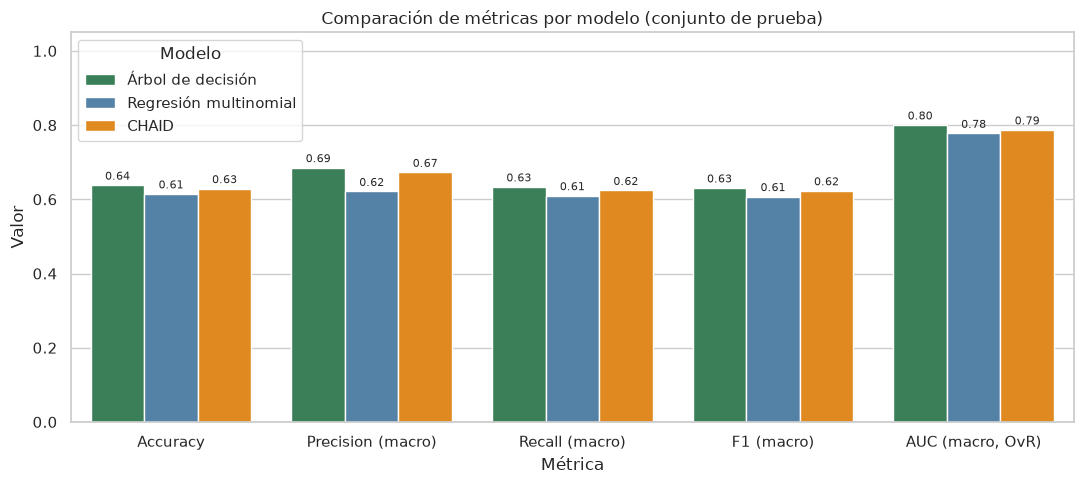

In [37]:
tabla_larga = tabla.reset_index(names="Modelo").melt(id_vars="Modelo", var_name="Métrica", value_name="Valor")
plt.figure(figsize=(11, 5))
ax = sns.barplot(data=tabla_larga, x="Métrica", y="Valor", hue="Modelo", palette=colores)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=8, padding=2)
plt.ylim(0, 1.05)
plt.title("Comparación de métricas por modelo (conjunto de prueba)")
plt.tight_layout()
plt.savefig(FIG_DIR + "p32_7_metricas.png", dpi=150)
plt.show()

In [38]:
# Desempeño por clase: precision, recall y AUC uno-contra-resto
filas = []
for nombre in predicciones:
    p = precision_score(y_test, predicciones[nombre], average=None)
    r = recall_score(y_test, predicciones[nombre], average=None)
    for k in range(3):
        filas.append({"Modelo": nombre, "Clase": NOMBRES[k], "Precision": p[k], "Recall": r[k], "AUC (OvR)": curvas_roc[nombre][k][2]})
por_clase = pd.DataFrame(filas)
por_clase.pivot(index="Modelo", columns="Clase", values=["Precision", "Recall", "AUC (OvR)"]).reindex(columns=NOMBRES, level=1).round(3)

Precision               Recall               AUC (OvR)  \
Clase                      Baja  Media   Alta   Baja  Media   Alta      Baja   
Modelo                                                                         
CHAID                     0.577  0.847  0.595  0.750  0.447  0.674     0.798   
Regresión multinomial     0.599  0.660  0.605  0.738  0.465  0.627     0.811   
Árbol de decisión         0.593  0.868  0.595  0.753  0.436  0.711     0.813   

                                     
Clase                  Media   Alta  
Modelo                               
CHAID                  0.755  0.808  
Regresión multinomial  0.724  0.798  
Árbol de decisión      0.760  0.828

##### 7.2: Curvas ROC conjuntas (uno contra resto, una gráfica por clase)

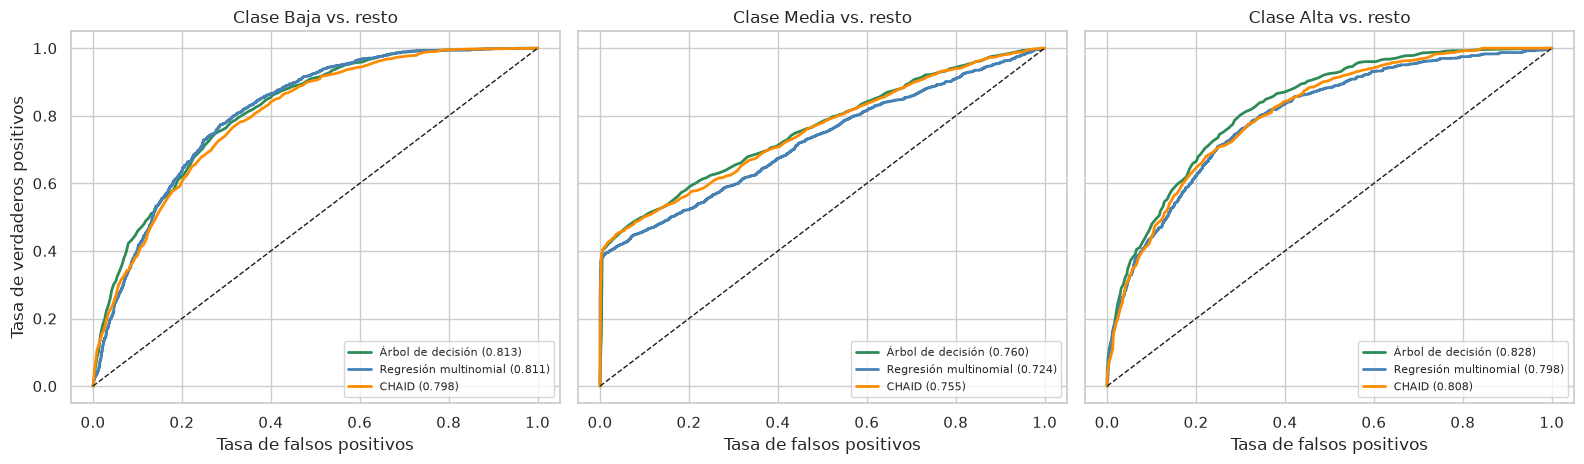

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
for k, ax in enumerate(axes):
    for nombre in curvas_roc:
        fpr, tpr, auc = curvas_roc[nombre][k]
        ax.plot(fpr, tpr, lw=2, color=colores[nombre], label=f"{nombre} ({auc:.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_title(f"Clase {NOMBRES[k]} vs. resto")
    ax.set_xlabel("Tasa de falsos positivos")
    ax.legend(loc="lower right", fontsize=8)
axes[0].set_ylabel("Tasa de verdaderos positivos")
plt.tight_layout()
plt.savefig(FIG_DIR + "p32_7_roc_conjunta.png", dpi=150)
plt.show()

##### 7.3: Matrices de confusión lado a lado

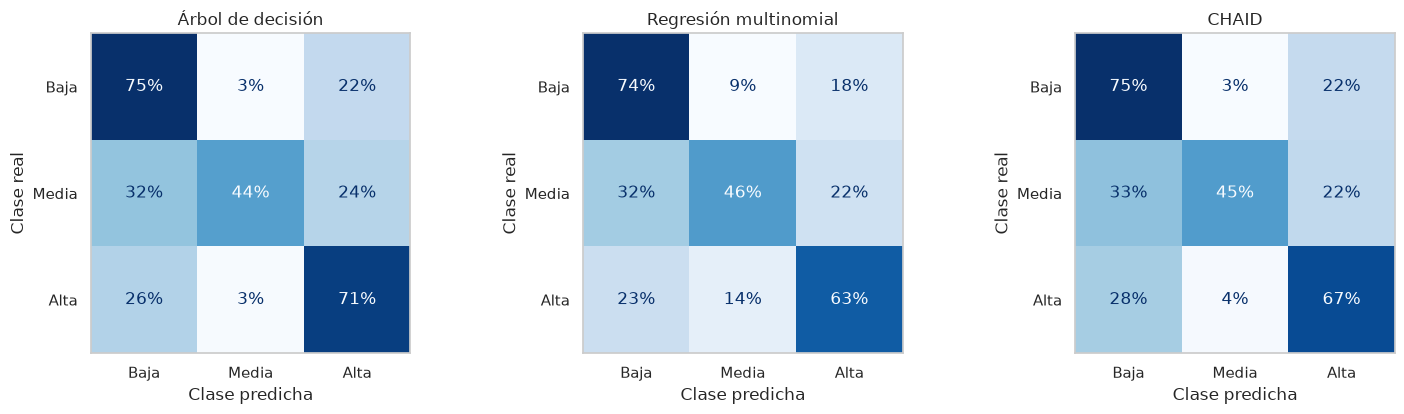

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, nombre in zip(axes, predicciones):
    ConfusionMatrixDisplay.from_predictions(y_test, predicciones[nombre], display_labels=NOMBRES, normalize="true",
                                            values_format=".0%", cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(nombre); ax.grid(False)
    ax.set_xlabel("Clase predicha"); ax.set_ylabel("Clase real")
plt.tight_layout()
plt.savefig(FIG_DIR + "p32_7_matrices.png", dpi=150)
plt.show()

##### 7.4: Entrenamiento vs. prueba (¿hay sobreajuste?)

In [41]:
modelos_X = {"Árbol de decisión": (X_train, X_test), "Regresión multinomial": (X_train, X_test), "CHAID": (XC_train, XC_test)}
filas = []
for nombre, (Xtr, Xte) in modelos_X.items():
    m = modelos[nombre]
    filas.append({"Modelo": nombre,
                  "AUC entrenamiento": roc_auc_score(y_train, m.predict_proba(Xtr), multi_class="ovr"),
                  "AUC validación cruzada": {"Árbol de decisión": busqueda_arbol, "Regresión multinomial": busqueda_mult, "CHAID": busqueda_chaid}[nombre].best_score_,
                  "AUC prueba": resultados[nombre]["AUC (macro, OvR)"],
                  "Accuracy entrenamiento": accuracy_score(y_train, m.predict(Xtr)),
                  "Accuracy prueba": resultados[nombre]["Accuracy"]})
sobre = pd.DataFrame(filas).set_index("Modelo")
sobre["Brecha AUC (train - test)"] = sobre["AUC entrenamiento"] - sobre["AUC prueba"]
sobre.round(3)

,AUC entrenamiento,AUC validación cruzada,AUC prueba,Accuracy entrenamiento,Accuracy prueba,Brecha AUC (train - test)
Modelo,,,,,,
Árbol de decisión,0.836,0.804,0.800,0.664,0.638,0.035
Regresión multinomial,0.775,0.769,0.778,0.616,0.615,-0.003
CHAID,0.821,0.781,0.787,0.650,0.629,0.034


##### 7.5: Importancia de variables: ¿coinciden los modelos?

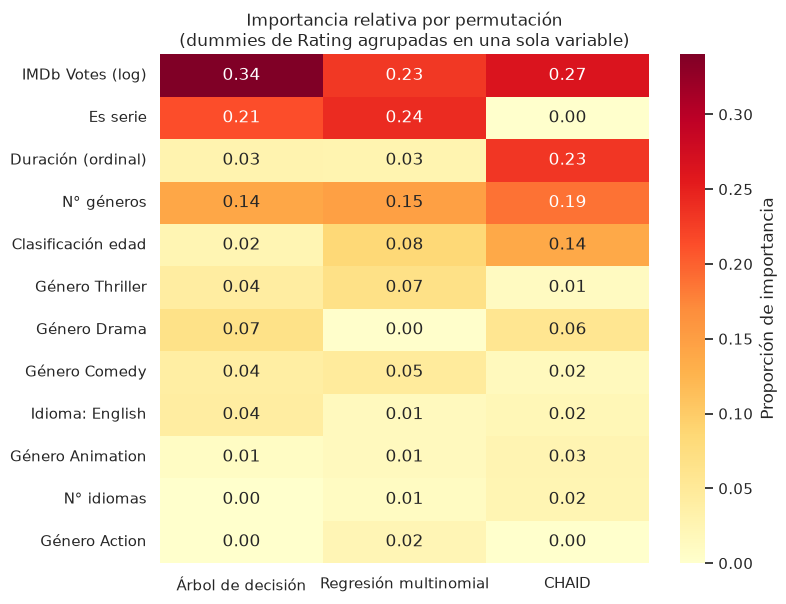

In [42]:
# Importancia por permutación normalizada (cada modelo suma 1). Las variables de CHAID se mapean a su equivalente en X.
equivalencia = {"Votos IMDb": "IMDb Votes (log)", "Año Netflix": "Año en Netflix", "Año estreno": "Año de estreno",
                "N géneros": "N° géneros", "N idiomas": "N° idiomas", "Duración": "Duración (ordinal)", "Tipo": "Es serie",
                "Inglés": "Idioma: English", "Clasificación edad": "Clasificación edad"}
imp_df = pd.DataFrame({n: importancias[n]["media"] for n in ["Árbol de decisión", "Regresión multinomial"]})
# Para agrupar las variables dummies de edad y la de género se suman bajo un mismo nombre
def agrupa(nombre):
    if nombre.startswith("Rating:"): return "Clasificación edad"
    if nombre.startswith("Género: "): return "Género " + nombre.split(": ")[1]
    return nombre
imp_df.index = [agrupa(i) for i in imp_df.index]
imp_df = imp_df.groupby(level=0).sum()
ch = importancias["CHAID"]["media"].rename(lambda i: equivalencia.get(i, i.replace("Género ", "Género ")))
imp_df["CHAID"] = ch.groupby(level=0).sum().reindex(imp_df.index).fillna(0)
imp_norm = imp_df.clip(lower=0) / imp_df.clip(lower=0).sum()
top_vars = imp_norm.max(axis=1).sort_values(ascending=False).head(12).index

plt.figure(figsize=(8, 6.2))
sns.heatmap(imp_norm.loc[top_vars], annot=True, fmt=".2f", cmap="YlOrRd", cbar_kws={"label": "Proporción de importancia"})
plt.title("Importancia relativa por permutación\n(dummies de Rating agrupadas en una sola variable)")
plt.tight_layout()
plt.savefig(FIG_DIR + "p32_7_importancia.png", dpi=150)
plt.show()

##### 7.6: Análisis de sensibilidad: ¿qué pasa si incluimos `Hidden Gem Score`?

Se reajustan los tres modelos con los mismos hiperparámetros agregando esa variable.

In [43]:
X_hg, XC_hg = X.assign(**{"Hidden Gem Score": df["Hidden Gem Score"]}), XC.assign(**{"Hidden Gem Score": quintiles(df["Hidden Gem Score"])})
X_hg_tr, X_hg_te, XC_hg_tr, XC_hg_te = X_hg.loc[idx_train], X_hg.loc[idx_test], XC_hg.loc[idx_train], XC_hg.loc[idx_test]

sens = {}
for nombre, base, (Xtr, Xte) in [("Árbol de decisión", arbol, (X_hg_tr, X_hg_te)),
                                 ("Regresión multinomial", mult, (X_hg_tr, X_hg_te)),
                                 ("CHAID", clone(chaid).set_params(ordinales=ORDINALES + ["Hidden Gem Score"]), (XC_hg_tr, XC_hg_te))]:
    m = clone(base).fit(Xtr, y_train)
    sens[nombre] = {"AUC sin Hidden Gem": resultados[nombre]["AUC (macro, OvR)"],
                    "AUC con Hidden Gem": roc_auc_score(y_test, m.predict_proba(Xte), multi_class="ovr"),
                    "Accuracy sin Hidden Gem": resultados[nombre]["Accuracy"],
                    "Accuracy con Hidden Gem": accuracy_score(y_test, m.predict(Xte))}
pd.DataFrame(sens).T.round(3)

,AUC sin Hidden Gem,AUC con Hidden Gem,Accuracy sin Hidden Gem,Accuracy con Hidden Gem
Árbol de decisión,0.800,0.947,0.638,0.826
Regresión multinomial,0.778,0.825,0.615,0.671
CHAID,0.787,0.885,0.629,0.716


- **Ranking:** el árbol queda arriba (accuracy 0.638, AUC 0.800), CHAID lo sigue de cerca (0.629, 0.787) y la regresión multinomial queda abajo (0.615, 0.778). Entre árbol y CHAID hay unos 40 títulos de diferencia en *accuracy* y 0.013 de AUC, del orden de la variación entre pliegues de la validación cruzada (desviación de 0.006 a 0.012).
- **Por clase**, los tres coinciden: Alta y Baja se separan mejor (AUC 0.80-0.83) que Media (0.72-0.76). El recall de Media es el más bajo en los tres (0.44-0.47). La precisión de Media es alta en el árbol y en CHAID (0.87 y 0.85) por el grupo sin géneros.
- **Errores graves:** regresión 13.7%, árbol 16.0%, CHAID 16.9%.
- **Sobreajuste (7.4):** brecha de AUC entre entrenamiento y prueba de 0.035 en el árbol, 0.034 en CHAID y -0.003 en la regresión, que es la más estable.
- **Variables (7.5):** coinciden en lo principal: votos, tipo de título (serie / duración corta) y número de géneros, y después Drama, Thriller, Comedia y la clasificación por edad. En CHAID `Duración` hace el papel de `Es serie`.
- **Sensibilidad (7.6):** al agregar `Hidden Gem Score`, el AUC del árbol sube de 0.800 a 0.947 (*accuracy* de 0.638 a 0.826), el de CHAID de 0.787 a 0.885 y el de la regresión de 0.778 a 0.825. Sin esa variable, el AUC está entre 0.78 y 0.80.

##### 7.7: Conclusión general de la comparación

| Criterio | Árbol de decisión | Regresión multinomial | CHAID |
|---|---|---|---|
| Accuracy | **0.638** | 0.615 | 0.629 |
| AUC macro (OvR) | **0.800** | 0.778 | 0.787 |
| F1 macro | **0.631** | 0.607 | 0.623 |
| Errores graves (Baja ↔ Alta) | 16.0% | **13.7%** | 16.9% |
| Brecha AUC train-test | 0.035 | **-0.003** | 0.034 |
| Interpretabilidad | Reglas (127 hojas; se leen los primeros niveles) | Coeficientes por variable y clase | Segmentos con pruebas χ² (140 hojas; bastan 2 niveles) |
| Variables categóricas | Necesita dummies | Necesita dummies y estandarizar | Las usa directamente |
| Hiperparámetros | 3 (profundidad, hoja mínima, poda) | 1 (C) | 2 (profundidad, tamaño de nodo) |

- El **árbol de decisión** es el de mejor desempeño en accuracy, AUC y F1 (63.8% contra un piso de 35.7%), aunque CHAID queda muy cerca.
- La **regresión multinomial** rinde algo menos, pero es la más estable (sin brecha entre entrenamiento y prueba), comete menos errores graves y da coeficientes fáciles de explicar.
- **CHAID** es el más útil para describir segmentos (por ejemplo, los títulos de 2 o 3 géneros y menos de 30 minutos son 60% de calidad Alta), pero con 140 hojas solo se puede leer en sus primeros niveles.
- Ningún modelo pasa de 64% de accuracy: con variables de catálogo no se captura la calidad percibida, y la clase Media es la que peor se separa.
- Agregar `Hidden Gem Score` subiría el AUC del árbol hasta 0.95, pero esa mejora viene de que el índice casi reconstruye la calificación, no de que el modelo sea mejor.